# Daily schedules and annual calendars

Understand the current 24-value schedule contract and its implications for representing diverse use patterns.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

A `ScheduleSpec` is a 24-value daily profile. `ScheduleSpec.constant(value)` is shorthand for repeating one value across those hours. The same type can hold temperatures or dimensionless fractions; the owning field determines the physical meaning and additional validation.

In the workflow diagram, schedules enter through building operations, after a shape is already inspectable. The current API repeats the same daily pattern on the validated annual calendar. Week and year plots below expand it for explanation; they do not create weekday, weekend, holiday or stochastic occupancy support.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Define a daily profile

ScheduleSpec accepts exactly 24 hourly values. The current compiler repeats this day; it has no separate weekday, weekend or holiday schedule input.

### Read the code and output

The setback profile lowers heating control to 18°C overnight and keeps 21°C during the selected daytime hours. This is a control input, not a prediction of indoor temperature. `len(values) == 24` checks the shape of the schedule rather than proving the setpoints are suitable for a particular use.

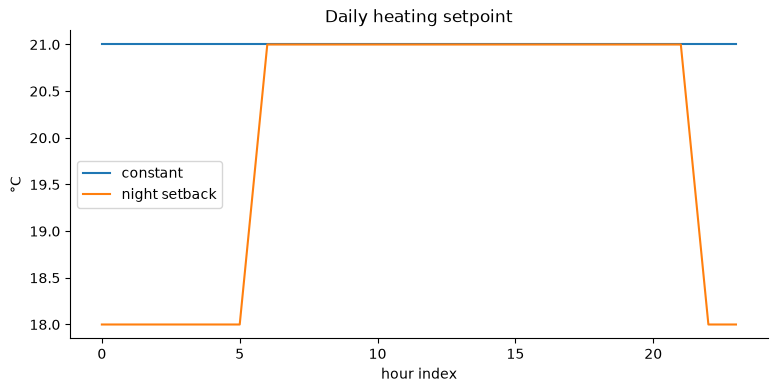

,field,value
0,values_per_day,24
1,hours_2023,8760
2,hours_2024,8784


,field,value
0,values_per_day,24
1,hours_2023,8760
2,hours_2024,8784


In [2]:
from epsm_core.weather import hourly_axis
constant = ScheduleSpec.constant(21)
setback = ScheduleSpec(values=tuple(18 if h<6 or h>=22 else 21 for h in range(24)))
assert len(setback.values)==24
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({"constant":constant.values,"night setback":setback.values}).plot(ax=ax, xlabel="hour index",ylabel="°C",title="Daily heating setpoint")
plt.show(); plt.close(fig)
table({"values_per_day":len(setback.values),"hours_2023":len(hourly_axis(2023)),"hours_2024":len(hourly_axis(2024))})

## Preview repetition explicitly

The week shown below is a visualization of daily repetition, not a new weekly schedule feature. This limitation matters for schools and offices.

### Read the code and output

`np.tile` repeats a profile for plotting. Identical columns in the annual heatmap are expected because this example has no seasonal schedule change. A school with holiday shutdowns cannot be represented faithfully by these repeated-day plots alone; that is a limit to disclose in a diversity study.

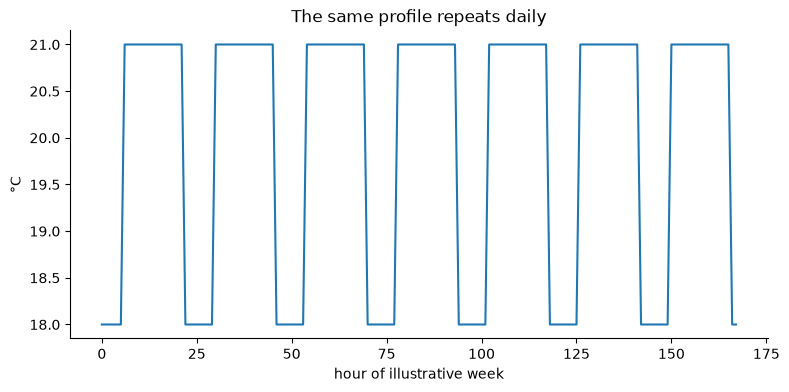

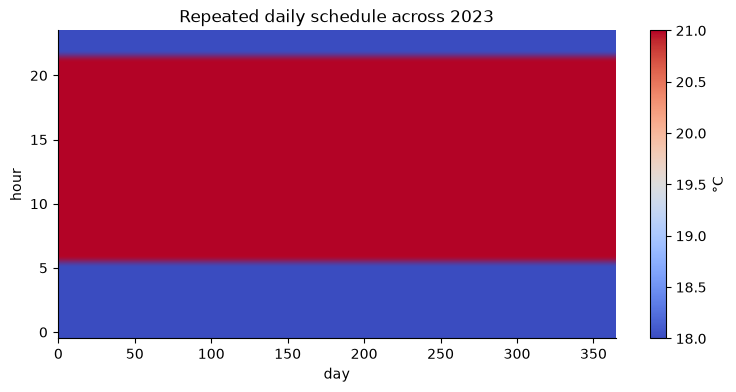

In [3]:
week = np.tile(setback.values,7)
fig, ax = plt.subplots(figsize=(9, 4))
plt.plot(np.arange(168),week); plt.xlabel("hour of illustrative week"); plt.ylabel("°C"); plt.title("The same profile repeats daily"); plt.show(); plt.close(fig)
annual = np.tile(setback.values,365).reshape(365,24)
fig, ax = plt.subplots(figsize=(9, 4))
plt.imshow(annual.T,aspect="auto",origin="lower",cmap="coolwarm"); plt.colorbar(label="°C"); plt.xlabel("day"); plt.ylabel("hour"); plt.title("Repeated daily schedule across 2023"); plt.show(); plt.close(fig)

## Reject malformed daily inputs

Validation stops unsupported lengths before a model is compiled. Setpoint schedules use temperatures; fractional schedules receive additional checks through UseSpec.

### Read the code and output

The deliberately short input tests early rejection of a malformed schedule. Valid fraction ranges and setpoint relationships are checked through their owning specifications as well. Keep units visible in plots so that a schedule of 0–1 fractions is not confused with a temperature curve.

In [4]:
from pydantic import ValidationError
try: ScheduleSpec(values=(1.,)*23)
except ValidationError as error: print("Expected rejection:",error.errors()[0]["msg"])
else: raise AssertionError("23-hour schedule was accepted")

Expected rejection: Tuple should have at least 24 items after validation, not 23


## Interpretation and next experiment

Describe schedule diversity honestly within the current daily-profile API. Do not claim weekday/weekend fidelity from a repeated daily curve.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.